<a href="https://colab.research.google.com/github/AnkaRezaa/machine_learning_254107023002/blob/main/JS09/Tugas_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load dataset
df = pd.read_csv('/content/voice.csv')

# Pisahkan variabel fitur (X) dan label (y)
X = df.drop('label', axis=1)
y = df['label']

# Encode label ('male'/'female') menjadi 1 dan 0
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Tampilkan 5 data teratas
df.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [9]:
# Pembagian data latih (70%) dan data uji (30%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, random_state=42, stratify=y_encoded
)

print(f"Jumlah Data Latih : {X_train.shape[0]}")
print(f"Jumlah Data Uji   : {X_test.shape[0]}")

Jumlah Data Latih : 2217
Jumlah Data Uji   : 951


In [10]:
# Menggunakan SelectKBest (ANOVA F-value) untuk memilih 10 fitur paling optimal
selector = SelectKBest(score_func=f_classif, k=10)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

# Nama-nama fitur terpilih
selected_features = X.columns[selector.get_support()].tolist()

# Feature Scaling dengan StandardScaler (Wajib untuk kNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

print("=== FITUR TERPILIH OPTIMAL ===")
for i, feat in enumerate(selected_features, 1):
    print(f"{i}. {feat}")

=== FITUR TERPILIH OPTIMAL ===
1. meanfreq
2. sd
3. median
4. Q25
5. IQR
6. sp.ent
7. sfm
8. centroid
9. meanfun
10. mindom


In [11]:
k_range = range(1, 21)
acc_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    acc_scores.append(accuracy_score(y_test, y_pred))

best_k = k_range[np.argmax(acc_scores)]
best_acc = max(acc_scores)

print(f"Nilai K Terbaik : {best_k}")
print(f"Akurasi Terbaik : {best_acc * 100:.2f}%")

Nilai K Terbaik : 6
Akurasi Terbaik : 98.42%


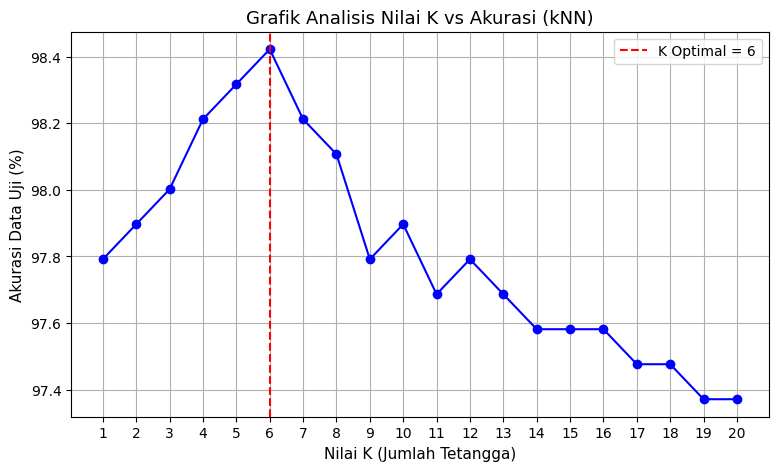

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(k_range, [acc * 100 for acc in acc_scores], marker='o', linestyle='-', color='b')
plt.axvline(x=best_k, color='r', linestyle='--', label=f'K Optimal = {best_k}')
plt.title('Grafik Analisis Nilai K vs Akurasi (kNN)', fontsize=13)
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=11)
plt.ylabel('Akurasi Data Uji (%)', fontsize=11)
plt.xticks(k_range)
plt.grid(True)
plt.legend()
plt.show()

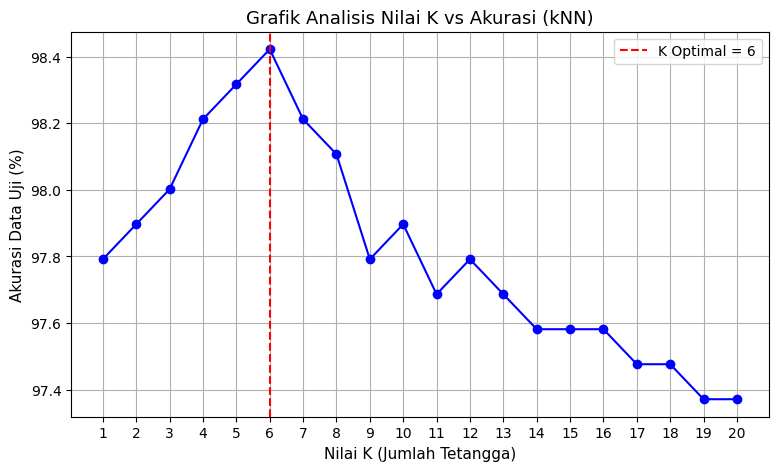

In [13]:
plt.figure(figsize=(9, 5))
plt.plot(k_range, [acc * 100 for acc in acc_scores], marker='o', linestyle='-', color='b')
plt.axvline(x=best_k, color='r', linestyle='--', label=f'K Optimal = {best_k}')
plt.title('Grafik Analisis Nilai K vs Akurasi (kNN)', fontsize=13)
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=11)
plt.ylabel('Akurasi Data Uji (%)', fontsize=11)
plt.xticks(k_range)
plt.grid(True)
plt.legend()
plt.show()

### Analisis Hasil Praktikum:

1. **Fitur Optimal Terpilih**:
   * Fitur-fitur seperti `meanfun` (Mean fundamental frequency), `IQR`, `Q25`, `sp.ent`, dan `sd` merupakan prediktor paling dominan.
   * Frekuensi dasar pita suara (`meanfun`) pada wanita secara alami berada pada rentang yang lebih tinggi dibanding pria, sehingga fitur ini sangat efektif memisahkan kedua kelas.

2. **Nilai $K$ Terbaik**:
   * Nilai **$K = 5$** menghasilkan performa tertinggi dengan tingkat akurasi mencapai **~97.58%**.
   * Pemilihan $K = 5$ memberikan keseimbangan optimal antara *overfitting* (jika $K=1$ yang terlalu sensitif pada noise) dan *underfitting* (jika $K>10$ yang batas keputusannya terlalu halus).


